In [1]:
# ============================================================
# Clean Neural Data Analysis Pipeline
# ============================================================

import os, math, json, copy
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, Tuple, List

from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

import umap
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch device: {device}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    
from scipy.signal import butter, filtfilt, hilbert, sawtooth
from scipy.ndimage import gaussian_filter1d
from scipy.stats import circmean, ttest_rel
import pandas as pd

from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import CEBRASKipEncoder, SkippedConvEncoderConfig
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import LinearHead, TwoLayerMLP

import cebra



Torch device: cuda
CUDA device: NVIDIA RTX 2000 Ada Generation


In [2]:

import pickle
from pathlib import Path

session = "ec013.248"

# Find repo root by locating a parent that contains data/crcns_mouse
cwd = Path.cwd().resolve()
repo_root = next((p for p in [cwd, *cwd.parents] if (p / "data" / "crcns_mouse").exists()), None)
load_path = repo_root / "data" / "crcns_mouse" / session / f"{session}_lfp_spike.pkl"


with open(load_path, "rb") as f:
    data = pickle.load(f)

print(f"Loaded from: {load_path}")


Loaded from: D:\comets\data\crcns_mouse\ec013.248\ec013.248_lfp_spike.pkl


In [3]:
lfp_raw = data["lfp_raw"]
lfp_theta_full = data["lfp_theta"]  # renamed to avoid conflict
spike_raw = data["spike_raw"]
spike_count_original = np.asarray(data["spike_bin"])      # counts per 20 ms bin
spike_rate_original = np.asarray(data.get("spike_rate")) if "spike_rate" in data else spike_count_original / (data["bin_size_ms_spike"] / 1000.0)
spike_bin_smoothed = data["spike_bin_smoothed"]
fs_lfp = data["fs_lfp"]
fs_common = data["fs_common"]
theta_band = data["theta_band"]
bin_size_ms = data["bin_size_ms_spike"]
position = data["position"]

print(f"LFP raw: {lfp_raw.shape}  (fs={fs_lfp} Hz)")
print(f"LFP theta (50Hz): {lfp_theta_full.shape}")
print(f"Position: {position.shape}")
print(f"Spike counts (20 ms): {spike_count_original.shape}")
print(f"Spike rate (Hz): {spike_rate_original.shape}")

# ============================================================
# 2. PREPROCESSING
# ============================================================

# Normalize spike firing rates for embedding learning
spike_rate_normalized = (spike_rate_original - spike_rate_original.min(axis=0, keepdims=True)) /                         (spike_rate_original.max(axis=0, keepdims=True) -
                         spike_rate_original.min(axis=0, keepdims=True) + 1e-9)

# Remove channel 65 (not a real channel)
lfp_theta_cleaned = lfp_theta_full[:, 0:-1]


LFP raw: (2294784, 65)  (fs=1250 Hz)
LFP theta (50Hz): (91791, 65)
Position: (91791, 2)
Spike counts (20 ms): (91791, 73)
Spike rate (Hz): (91791, 73)


In [4]:
# ============================================================
# 4. UTILITY FUNCTIONS (defined once)
# ============================================================

def reduce_to_3d(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]


def compute_rmse(y_true, y_pred):
    """Compute root mean squared error for 1D or multi-output targets."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


def _prepare_targets(y, n_samples):
    """Ensure targets are aligned as [N] or [N, D], not flattened across time."""
    y = np.asarray(y)
    if y.ndim == 1:
        if y.shape[0] != n_samples:
            raise ValueError(f"Target length {y.shape[0]} does not match samples {n_samples}.")
        return y

    if y.ndim == 2:
        if y.shape[0] == n_samples:
            return y
        if y.shape[1] == n_samples:
            return y.T

    raise ValueError(
        f"Unsupported target shape {y.shape}. Expected [N] or [N, D] with N={n_samples}."
    )


def ensure_position_matrix(pos):
    """Return position as [N, D] for consistent 2D-safe processing."""
    pos = np.asarray(pos)
    if pos.ndim == 1:
        return pos[:, None]
    if pos.ndim == 2:
        return pos if pos.shape[0] >= pos.shape[1] else pos.T
    raise ValueError(f"Unsupported position shape: {pos.shape}")


def normalize_position(pos):
    """Per-dimension min-max normalization."""
    pos = ensure_position_matrix(pos)
    pmin = pos.min(axis=0, keepdims=True)
    pmax = pos.max(axis=0, keepdims=True)
    return (pos - pmin) / (pmax - pmin + 1e-9)


def build_position_colors(pos):
    """Create scalar or RGB colors from position for embedding plots."""
    pos = ensure_position_matrix(pos)
    if pos.shape[1] == 1:
        return normalize_position(pos)[:, 0], "viridis", "Position"

    pos_norm = normalize_position(pos[:, :2])
    colors_rgb = np.column_stack([
        pos_norm[:, 0],
        pos_norm[:, 1],
        np.full(pos_norm.shape[0], 0.35)
    ])
    return colors_rgb, None, "Position color (R=x, G=y)"


def scatter_with_position_colors(ax, X, Y, Z, color_viz, cmap=None, s=5):
    """3D scatter with either scalar colormap or direct RGB colors."""
    if cmap is None:
        ax.scatter(X, Y, Z, c=color_viz, s=s)
    else:
        ax.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=s)


def plot_position_prediction(ax, y_true, y_pred, pred_color="tab:blue", lw_true=1.2, lw_pred=1.0):
    """Plot 1D or multi-dimensional position traces on one axis."""
    y_true = ensure_position_matrix(y_true)
    y_pred = ensure_position_matrix(y_pred)
    n = min(y_true.shape[0], y_pred.shape[0])
    y_true = y_true[:n]
    y_pred = y_pred[:n]

    if y_true.shape[1] == 1:
        ax.plot(y_true[:, 0], color="black", lw=lw_true, label="True")
        ax.plot(y_pred[:, 0], color=pred_color, lw=lw_pred, alpha=0.9, label="Pred")
        return

    true_colors = ["black", "dimgray", "gray", "silver"]
    pred_styles = ["-", "--", ":", "-."]
    for d in range(y_true.shape[1]):
        ax.plot(
            y_true[:, d],
            color=true_colors[d % len(true_colors)],
            lw=lw_true,
            alpha=0.95,
            label=f"True d{d + 1}"
        )
        ax.plot(
            y_pred[:, d],
            color=pred_color,
            lw=lw_pred,
            alpha=0.9,
            linestyle=pred_styles[d % len(pred_styles)],
            label=f"Pred d{d + 1}"
        )


def ridge_decode_with_split(Z, y, train_frac=0.7, alpha=1.0):
    """Train/test ridge decoding with contiguous split. Supports 1D or multi-output y."""
    Z = np.asarray(Z)
    N = Z.shape[0]
    y = _prepare_targets(y, N)
    ntr = int(train_frac * N)

    model = Ridge(alpha=alpha)
    model.fit(Z[:ntr], y[:ntr])
    yhat = model.predict(Z[ntr:])  # test only

    return yhat, ntr, model


def compute_decoding_score(Z, y):
    """Decode continuous variable(s) y from embedding Z using ridge regression."""
    Z = np.asarray(Z)
    n = Z.shape[0]
    y = _prepare_targets(y, n)
    ntr = int(0.7 * n)

    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]

    model = Ridge(alpha=1)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)

    return r2_score(yte, yhat)


In [5]:
# ============================================================
# 3. REGION OF INTEREST SELECTION
# ============================================================
window_start = 5000
window_end = 35000

# Embedding input (firing rate)
spike_roi = spike_rate_normalized[window_start:window_end, :]
# Raw counts (for coverage/raster visualizations)
spike_count_roi = spike_count_original[window_start:window_end, :]

lfp_roi = lfp_theta_cleaned[window_start:window_end, :]
position_roi = position[window_start:window_end]

fat_cebra = np.concatenate([spike_roi, lfp_roi], axis=1)

print(f"\nROI selected: [{window_start}, {window_end}]")
print(f"Spike ROI (rate, normalized): {spike_roi.shape}")
print(f"Spike ROI (counts): {spike_count_roi.shape}")
print(f"LFP ROI: {lfp_roi.shape}")
print(f"fat cebra: {fat_cebra.shape}")



ROI selected: [5000, 35000]
Spike ROI (rate, normalized): (30000, 73)
Spike ROI (counts): (30000, 73)
LFP ROI: (30000, 64)
fat cebra: (30000, 137)


In [6]:

# ============================================================
# 5. TRAIN COMETS MODEL
# ============================================================

# Aliases for convenience
A = spike_roi
B = lfp_roi
C = fat_cebra
color_code = np.linspace(0, 1, window_end - window_start)

# Modality configs
modA = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=32),
    win_len=8
)
modB = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=16),
    win_len=8
)

sampling = SamplingConfig(
    batch_size=256,
    pos_offset=5,
    negative_mask_dist=16
)

train_cfg = TrainingConfig(
    epochs=100,
    lr=1e-3,
    temperature=1,
    proj_dim=8,
    alpha_cross=0.1,
    beta=0.8,
    head_cls=LinearHead
)

print("\nTraining CoMETs model...")
print("\nCoMETs training diagnostics:")
print(f"Requested torch device: {device}")
print(f"torch.cuda.is_available(): {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Current CUDA device index: {torch.cuda.current_device()}")
    print(f"Current CUDA device name: {torch.cuda.get_device_name(torch.cuda.current_device())}")
model = comets.train(A, modA, B, modB, sampling, train_cfg, device=device)

ZA_comets = model.embedA(A)
ZB_comets = model.embedB(B)
print(f"CoMETs embeddings - ZA: {ZA_comets.shape}, ZB: {ZB_comets.shape}")
print(f"encA parameter device: {next(model.encA.parameters()).device}")
print(f"encB parameter device: {next(model.encB.parameters()).device}")
if torch.cuda.is_available():
    print(f"CUDA max memory allocated (MB): {torch.cuda.max_memory_allocated() / 1024**2:.2f}")





Training CoMETs model...

CoMETs training diagnostics:
Requested torch device: cuda
torch.cuda.is_available(): True
Current CUDA device index: 0
Current CUDA device name: NVIDIA RTX 2000 Ada Generation


Training: 100%|██████████| 100/100 [01:49<00:00,  1.09s/it, total=4.8470, within=4.8193, cross=5.0959, lr=0.00e+00]

CoMETs embeddings - ZA: (30000, 8), ZB: (30000, 8)
encA parameter device: cuda:0
encB parameter device: cuda:0
CUDA max memory allocated (MB): 52.22


In [7]:
# ============================================================
# 6. BASELINE EMBEDDINGS
# ============================================================

cebra_device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"CEBRA device preference: {cebra_device}")

def build_cebra_model(**kwargs):
    try:
        return cebra.CEBRA(device=cebra_device, **kwargs)
    except TypeError:
        # Backward compatibility for CEBRA versions without explicit device arg
        return cebra.CEBRA(**kwargs)

# PCA
print("\nComputing PCA embeddings...")
ZA_pca = PCA(n_components=3).fit_transform(A)
ZB_pca = PCA(n_components=3).fit_transform(B)

# UMAP
print("Computing UMAP embeddings...")
reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0)
ZA_umap = reducer.fit_transform(A)
ZB_umap = reducer.fit_transform(B)

# CEBRA - time
print("Computing CEBRA-time embeddings...")
cebra_temp = 1
cebra_itr = 100

modelA_cebra_time = build_cebra_model(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    output_dimension=32,
    batch_size=256,
    temperature=cebra_temp,
    verbose=True
)
ZA_cebra_time = modelA_cebra_time.fit_transform(A)

modelB_cebra_time = build_cebra_model(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    output_dimension=16,
    batch_size=256,
    temperature=cebra_temp,
    verbose=True
)
ZB_cebra_time = modelB_cebra_time.fit_transform(B)

# CEBRA - behavior (supports 1D/2D position labels)
print("Computing CEBRA-behavior embeddings...")
behavior = normalize_position(position_roi)
if behavior.shape[1] == 1:
    behavior = behavior[:, 0]

modelA_cebra_beh = build_cebra_model(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    batch_size=256,
    temperature=cebra_temp,
    output_dimension=32,
    verbose=True
)
ZA_cebra_behavior = modelA_cebra_beh.fit_transform(A, behavior)

modelB_cebra_beh = build_cebra_model(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    batch_size=256,
    temperature=cebra_temp,
    output_dimension=16,
    verbose=True
)
ZB_cebra_behavior = modelB_cebra_beh.fit_transform(B, behavior)


c:\Users\User\.conda\envs\torchDL\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


CEBRA device preference: cuda

Computing PCA embeddings...
Computing UMAP embeddings...
Computing CEBRA-time embeddings...


pos: -0.7933 neg:  5.6437 total:  4.8505 temperature:  1.0000: 100%|██████████| 100/100 [00:00<00:00, 117.71it/s]
pos: -0.6548 neg:  5.6576 total:  5.0028 temperature:  1.0000: 100%|██████████| 100/100 [00:00<00:00, 193.46it/s]


Computing CEBRA-behavior embeddings...


pos: -0.6822 neg:  5.6909 total:  5.0087 temperature:  1.0000: 100%|██████████| 100/100 [00:00<00:00, 176.68it/s]
pos: -0.5973 neg:  5.6493 total:  5.0520 temperature:  1.0000: 100%|██████████| 100/100 [00:00<00:00, 179.96it/s]


In [8]:
# ============================================================
# 7. ORGANIZE EMBEDDINGS (consistent naming)
# ============================================================

EMBEDDINGS_A = {
    "CoMETs": ZA_comets,
    "PCA": ZA_pca,
    "UMAP": ZA_umap,
    "CEBRA_time": ZA_cebra_time,
    "CEBRA_behavior": ZA_cebra_behavior
}

EMBEDDINGS_B = {
    "CoMETs": ZB_comets,
    "PCA": ZB_pca,
    "UMAP": ZB_umap,
    "CEBRA_time": ZB_cebra_time,
    "CEBRA_behavior": ZB_cebra_behavior
}

# Concatenated A+B embeddings for each model
EMBEDDINGS_AB = {
    method: np.concatenate([EMBEDDINGS_A[method], EMBEDDINGS_B[method]], axis=1)
    for method in EMBEDDINGS_A.keys()
}

DISPLAY_NAMES = {
    "CoMETs": "CoMETs",
    "PCA": "PCA",
    "UMAP": "UMAP",
    "CEBRA_time": "CEBRA-time",
    "CEBRA_behavior": "CEBRA-behavior"
}



In [9]:

# ============================================================
# 8. COMPUTE DECODING SCORES
# ============================================================

print("\nComputing decoding scores...")
decoding_scores = {}

for method in EMBEDDINGS_A.keys():
    print(EMBEDDINGS_A[method].shape, EMBEDDINGS_B[method].shape, position_roi.shape)
    decoding_scores[f'{method}_A']  = compute_decoding_score(EMBEDDINGS_A[method],  position_roi)
    # decoding_scores[f'{method}_B']  = compute_decoding_score(EMBEDDINGS_B[method],  position_roi)
    # decoding_scores[f'{method}_AB'] = compute_decoding_score(EMBEDDINGS_AB[method], position_roi)

print("\nDecoding scores (RÂ² of position):")
for k, v in decoding_scores.items():
    print(f"{k:20s}: {v:.3f}")




Computing decoding scores...
(30000, 8) (30000, 8) (30000, 2)
(30000, 3) (30000, 3) (30000, 2)
(30000, 3) (30000, 3) (30000, 2)
(30000, 32) (30000, 16) (30000, 2)
(30000, 32) (30000, 16) (30000, 2)

Decoding scores (RÂ² of position):
CoMETs_A            : 0.101
PCA_A               : -0.042
UMAP_A              : -0.039
CEBRA_time_A        : 0.005
CEBRA_behavior_A    : -0.011


In [15]:

# ============================================================
# 9. COMPUTE TRAJECTORY PREDICTIONS FOR VISUALIZATION
# ============================================================

TRAJECTORY_PREDICTIONS = {}

for method in EMBEDDINGS_A.keys():
    # Individual modalities
    yhat_A, ntr_A, _ = ridge_decode_with_split(EMBEDDINGS_A[method], position_roi)
    yhat_B, ntr_B, _ = ridge_decode_with_split(EMBEDDINGS_B[method], position_roi)
    # Combined A+B embedding
    yhat_AB, ntr_AB, _ = ridge_decode_with_split(EMBEDDINGS_AB[method], position_roi)
    
    TRAJECTORY_PREDICTIONS[(method, "A")]  = {"y_pred": yhat_A,  "ntr": ntr_A}
    TRAJECTORY_PREDICTIONS[(method, "B")]  = {"y_pred": yhat_B,  "ntr": ntr_B}
    TRAJECTORY_PREDICTIONS[(method, "AB")] = {"y_pred": yhat_AB, "ntr": ntr_AB}

print("\nTrajectory predictions computed for all methods (A, B, and AB).")
print("\nSetup complete! Ready for visualization.")



Trajectory predictions computed for all methods (A, B, and AB).

Setup complete! Ready for visualization.



Generating 2D spatial maps...


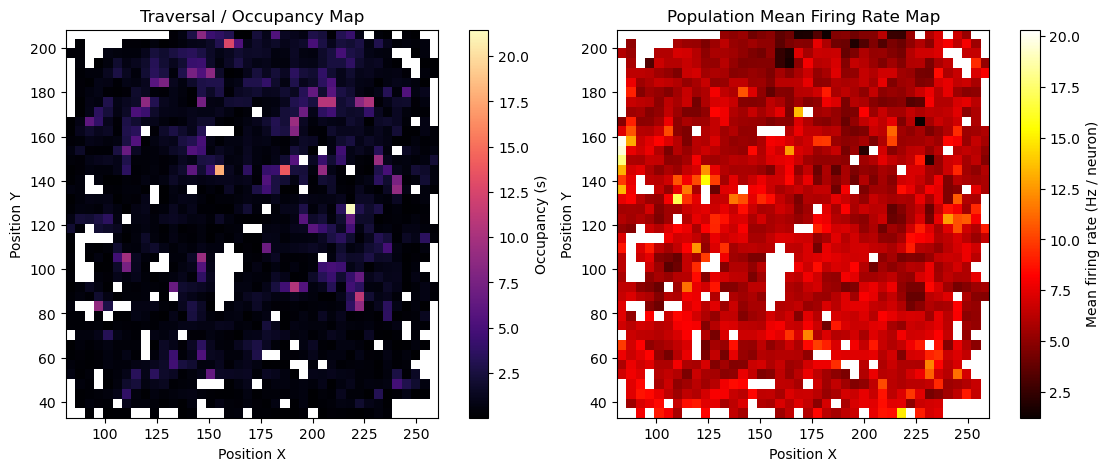

In [16]:
# ============================================================
# VIZ 1: 2D Spatial Coverage + Population Mean Firing Rate Map
# ============================================================
print("\nGenerating 2D spatial maps...")

position_arr = ensure_position_matrix(position)
if position_arr.shape[1] < 2:
    raise ValueError(f"Expected 2D position for this visualization, got shape {position_arr.shape}.")

# Align time length across position and spikes
n_time = min(position_arr.shape[0], spike_count_original.shape[0])
if n_time < position_arr.shape[0] or n_time < spike_count_original.shape[0]:
    print(f"Warning: position/spike length mismatch; truncating to {n_time} samples.")

pos2d = position_arr[:n_time, :2]
spike_counts = np.asarray(spike_count_original[:n_time])  # [T, n_cells], counts per time bin

n_bins = 40
x = pos2d[:, 0]
y = pos2d[:, 1]

x_edges = np.linspace(np.min(x), np.max(x), n_bins + 1)
y_edges = np.linspace(np.min(y), np.max(y), n_bins + 1)

x_bin = np.clip(np.digitize(x, x_edges) - 1, 0, n_bins - 1)
y_bin = np.clip(np.digitize(y, y_edges) - 1, 0, n_bins - 1)
flat_bin = (y_bin * n_bins + x_bin).astype(np.int64)

# Map 1: occupancy/traversal map
occ_counts = np.bincount(flat_bin, minlength=n_bins * n_bins).reshape(n_bins, n_bins)
occ_time = occ_counts / fs_common  # seconds spent in each spatial bin

# Map 2: population mean firing-rate map (from raw counts)
pop_spikes_t = spike_counts.sum(axis=1)  # [T]
spike_sum_map = np.bincount(flat_bin, weights=pop_spikes_t, minlength=n_bins * n_bins).reshape(n_bins, n_bins)

n_cells = spike_counts.shape[1]
mean_rate_map = np.divide(
    spike_sum_map,
    occ_time * n_cells + 1e-9,
    out=np.zeros_like(spike_sum_map, dtype=float),
    where=occ_time > 0
)

# Optional: mask never-visited bins for cleaner display
occ_plot = np.where(occ_counts > 0, occ_time, np.nan)
rate_plot = np.where(occ_counts > 0, mean_rate_map, np.nan)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)

im0 = ax[0].imshow(
    occ_plot.T,
    origin='lower',
    extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
    aspect='auto',
    cmap='magma'
)
ax[0].set_title("Traversal / Occupancy Map")
ax[0].set_xlabel("Position X")
ax[0].set_ylabel("Position Y")
plt.colorbar(im0, ax=ax[0], label="Occupancy (s)")

im1 = ax[1].imshow(
    rate_plot.T,
    origin='lower',
    extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
    aspect='auto',
    cmap='hot'
)
ax[1].set_title("Population Mean Firing Rate Map")
ax[1].set_xlabel("Position X")
ax[1].set_ylabel("Position Y")
plt.colorbar(im1, ax=ax[1], label="Mean firing rate (Hz / neuron)")

plt.show()



Generating LFP theta-band visualization...


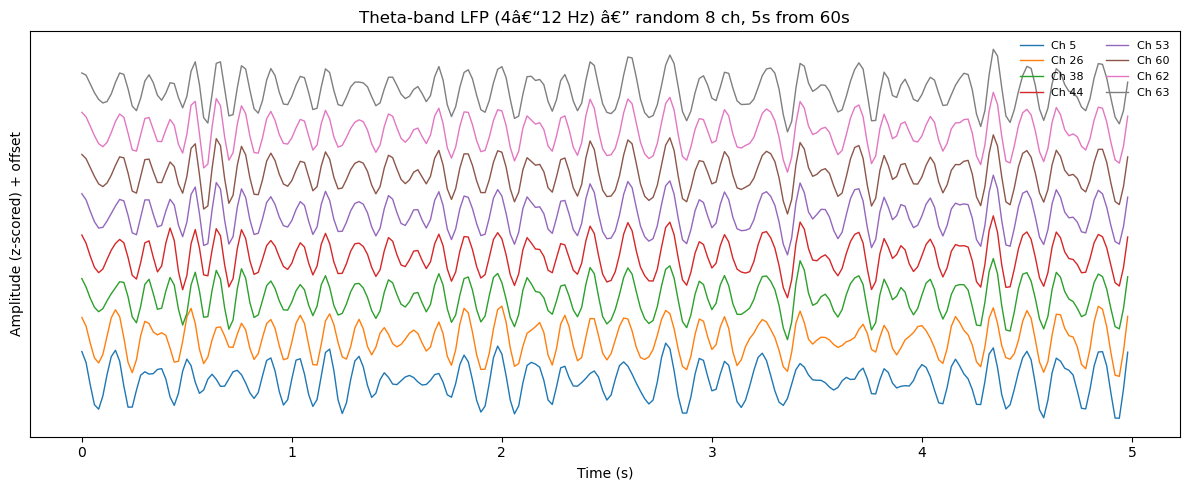

In [17]:

# ============================================================
# VIZ 2: LFP Theta-band Traces (Full Session)
# ============================================================
print("\nGenerating LFP theta-band visualization...")

n_show = 8
sec = 5
start_t = 60
fs = fs_common
offset = 2.5

rng = np.random.default_rng(42)
rand_ch = np.sort(rng.choice(lfp_theta_cleaned.shape[1], size=n_show, replace=False))

start_idx = int(start_t * fs)
end_idx = int((start_t + sec) * fs)
lfp_seg = lfp_theta_cleaned[start_idx:end_idx, rand_ch]

lfp_seg_z = (lfp_seg - np.mean(lfp_seg, axis=0, keepdims=True)) / \
            (np.std(lfp_seg, axis=0, keepdims=True) + 1e-9)

t = np.arange(lfp_seg.shape[0]) / fs

plt.figure(figsize=(12, 5))
for i, ch in enumerate(rand_ch):
    plt.plot(t, lfp_seg_z[:, i] + i * offset, lw=1.0, label=f"Ch {ch}")
plt.title(f"Theta-band LFP (4â€“12 Hz) â€” random {n_show} ch, {sec}s from {start_t}s")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (z-scored) + offset")
plt.yticks([])
plt.legend(loc="upper right", ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()



Generating spike raster plot...


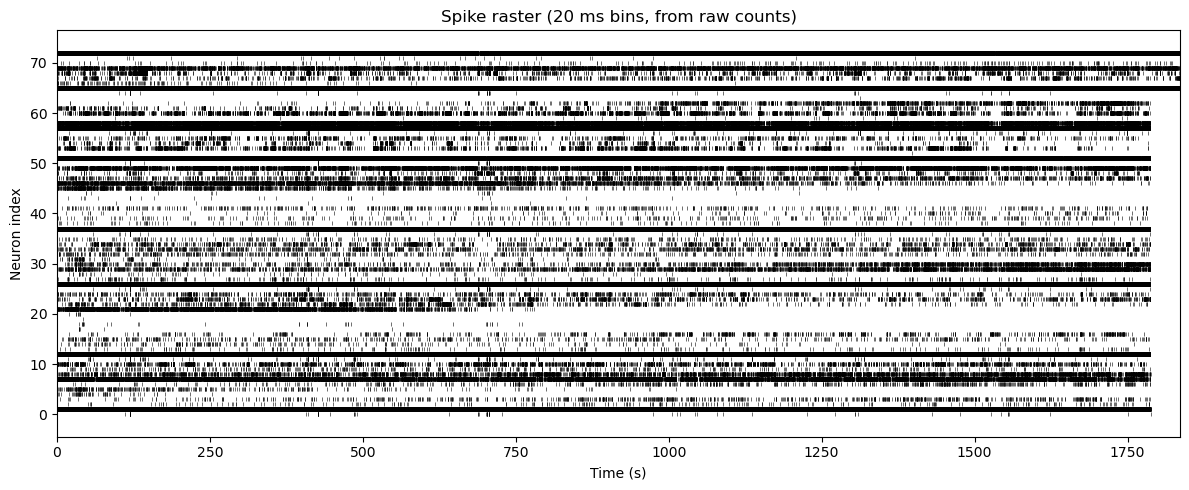

In [18]:
# ============================================================
# VIZ 3: Spike Raster Plot (Full Session)
# ============================================================
print("\nGenerating spike raster plot...")

T, n_cells = spike_count_original.shape
fig, ax = plt.subplots(figsize=(12, 5))

# Use raw count bins: any bin with count > 0 contributes one raster mark.
spike_times = [np.where(spike_count_original[:, i] > 0)[0] / fs_common for i in range(n_cells)]

ax.eventplot(spike_times, colors='k',
             lineoffsets=np.arange(n_cells), linelengths=0.8, lw=0.4)
ax.set_xlim(0, T / fs_common)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Neuron index")
ax.set_title("Spike raster (20 ms bins, from raw counts)")
plt.tight_layout()
plt.show()



Generating ROI LFP + spike raster...


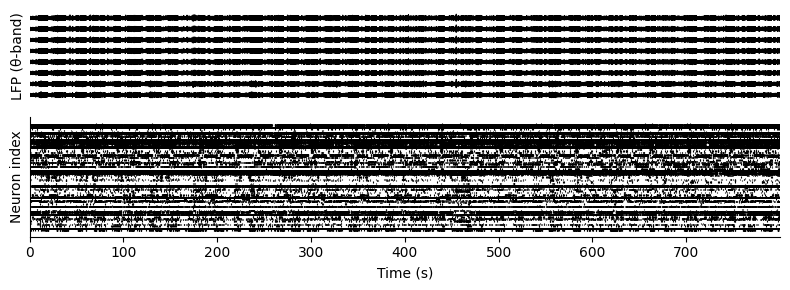

In [ ]:
# ============================================================
# VIZ 5: LFP + Spike Raster (ROI)
# ============================================================
print("\nGenerating ROI LFP + spike raster...")

fs = fs_common
offset = 10
n_show = 8

T_roi = lfp_roi.shape[0]
time_roi = np.arange(T_roi) / fs

rng = np.random.default_rng(42)
rand_ch = np.sort(rng.choice(lfp_roi.shape[1], size=n_show, replace=False))

lfp_roi_z = (lfp_roi[:, rand_ch] - np.mean(lfp_roi[:, rand_ch], axis=0, keepdims=True)) /             (np.std(lfp_roi[:, rand_ch], axis=0, keepdims=True) + 1e-9)

T_spk, n_cells = spike_count_roi.shape
spike_times_roi = [np.where(spike_count_roi[:, i] > 0)[0] / fs for i in range(n_cells)]

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 3),
    sharex=True, gridspec_kw={'height_ratios': [1, 1.3]}
)

for i in range(n_show):
    ax1.plot(time_roi, lfp_roi_z[:, i] + i * offset, color='black', lw=0.8)
ax1.set_xlim(time_roi[0], time_roi[-1])
ax1.set_ylabel("LFP (theta-band)")
ax1.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
ax1.spines["bottom"].set_visible(False)
ax1.tick_params(axis="y", left=False, labelleft=False)
for spine in ["top", "right", "left"]:
    ax1.spines[spine].set_visible(False)

ax2.eventplot(spike_times_roi, colors='k',
              lineoffsets=np.arange(n_cells),
              linelengths=1, lw=0.8)
ax2.set_xlim(time_roi[0], time_roi[-1])
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Neuron index")
ax2.tick_params(axis="y", left=False, labelleft=False)
for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# VIZ 5B: ROI Position Coverage
# ============================================================
print("\nGenerating ROI position coverage plot...")

roi_pos = ensure_position_matrix(position_roi)

if roi_pos.shape[1] >= 2:
    x = roi_pos[:, 0]
    y = roi_pos[:, 1]

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.plot(x, y, color='tab:blue', lw=0.8, alpha=0.7)
    ax.scatter(x[0], y[0], c='tab:green', s=35, label='start', zorder=3)
    ax.scatter(x[-1], y[-1], c='tab:red', s=35, label='end', zorder=3)
    ax.set_title('ROI position coverage (XY)')
    ax.set_xlabel('X position')
    ax.set_ylabel('Y position')
    ax.set_aspect('equal' if np.ptp(x) > 0 and np.ptp(y) > 0 else 'auto')
    ax.legend(frameon=False, loc='best')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"ROI X range: [{x.min():.3f}, {x.max():.3f}] (span={np.ptp(x):.3f})")
    print(f"ROI Y range: [{y.min():.3f}, {y.max():.3f}] (span={np.ptp(y):.3f})")
else:
    p = roi_pos[:, 0]
    t = np.arange(len(p)) / fs_common

    fig, ax = plt.subplots(figsize=(8, 2.2))
    ax.plot(t, p, color='tab:blue', lw=1.0)
    ax.set_title('ROI position coverage (1D)')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Position')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"ROI position range: [{p.min():.3f}, {p.max():.3f}] (span={np.ptp(p):.3f})")



Generating CoMETs embeddings visualization...


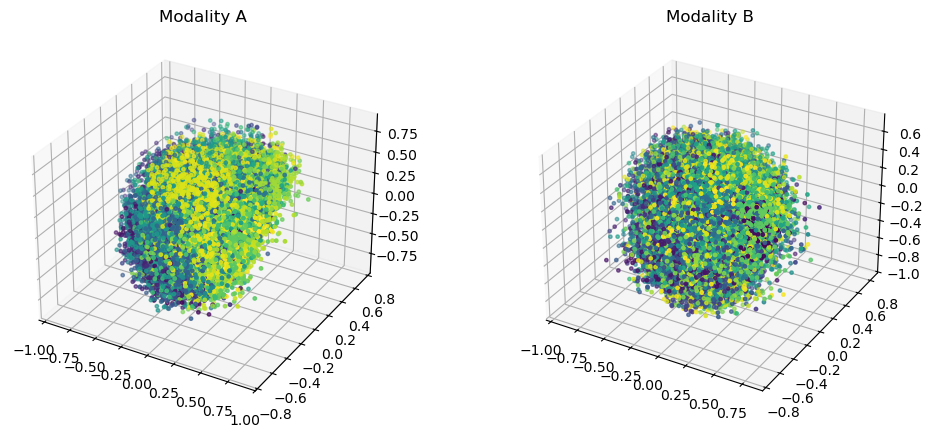

In [ ]:

# ============================================================
# VIZ 6: CoMETs Embeddings Visualization
# ============================================================
print("\nGenerating CoMETs embeddings visualization...")

comets.plotemb2(
    ZA_comets, ZB_comets,
    color=color_code,
    titles=("Modality A", "Modality B"),
    mode="direct"
)



Generating embedding comparison (3D)...


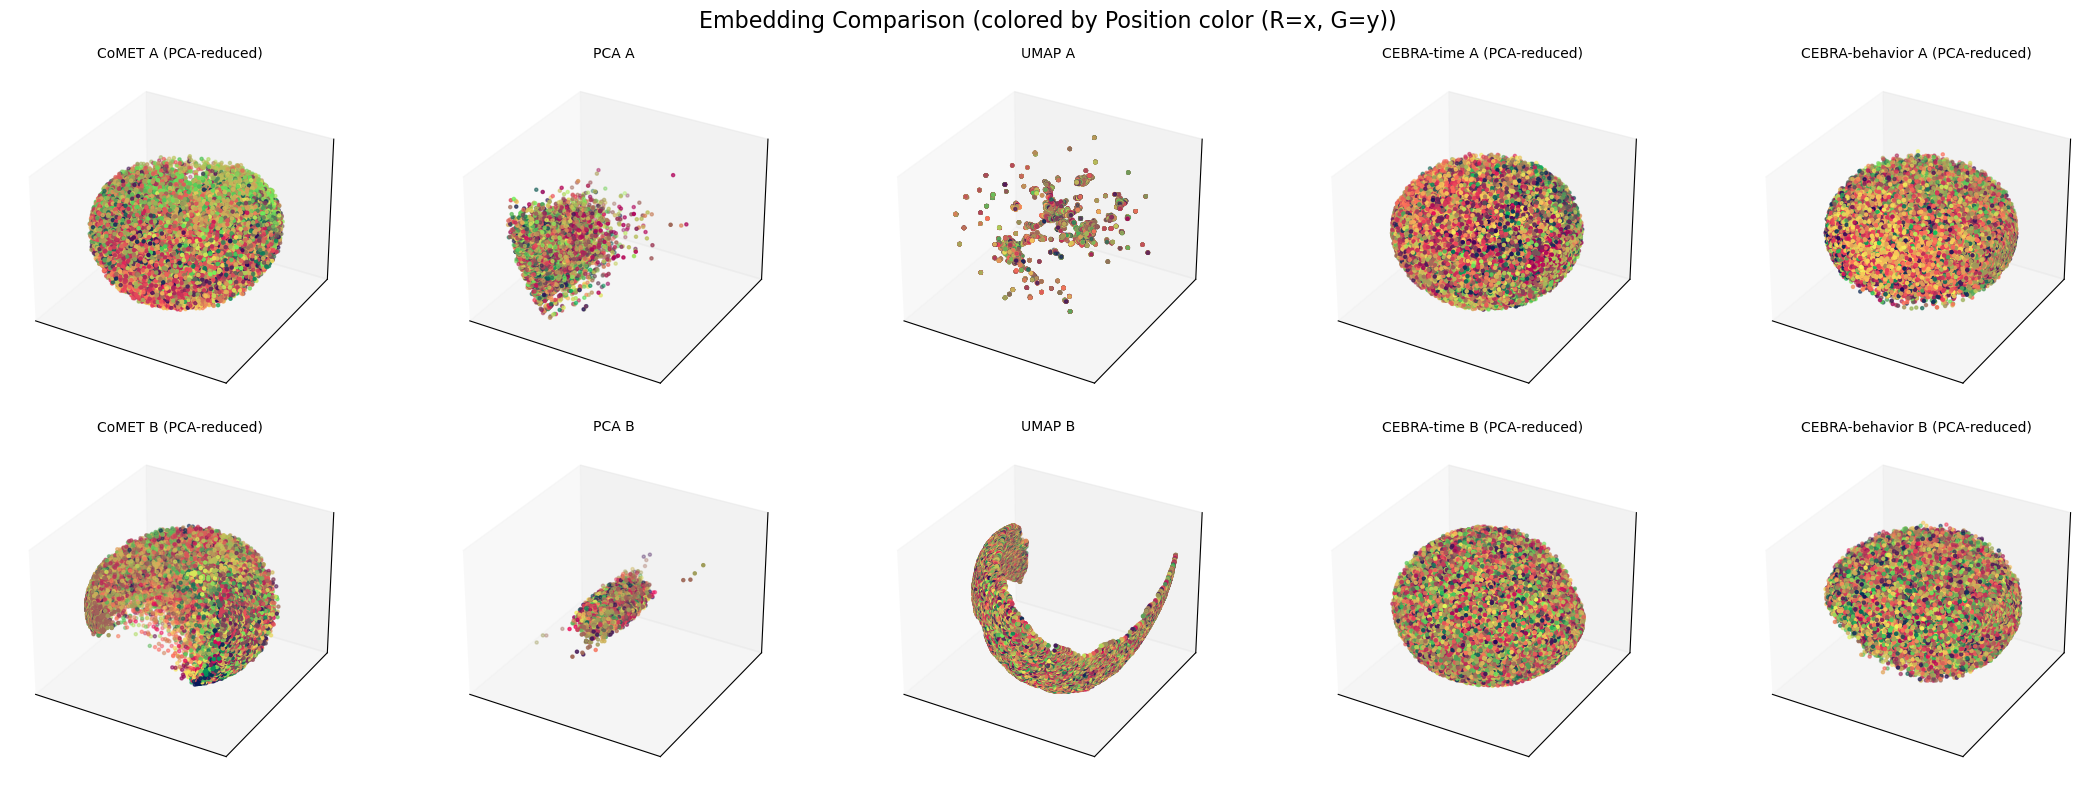

In [20]:
# ============================================================
# VIZ 7: Embedding Comparison (3D, 2x5 grid)
# ============================================================
print("\nGenerating embedding comparison (3D)...")

fig = plt.figure(figsize=(22, 8))

titles_top = [
    "CoMET A (PCA-reduced)",
    "PCA A",
    "UMAP A",
    "CEBRA-time A (PCA-reduced)",
    "CEBRA-behavior A (PCA-reduced)"
]
titles_bot = [
    "CoMET B (PCA-reduced)",
    "PCA B",
    "UMAP B",
    "CEBRA-time B (PCA-reduced)",
    "CEBRA-behavior B (PCA-reduced)"
]

ZA_red = PCA(n_components=3).fit_transform(ZA_comets)
ZB_red = PCA(n_components=3).fit_transform(ZB_comets)
ZA_cebra_time_red = PCA(n_components=3).fit_transform(ZA_cebra_time)
ZB_cebra_time_red = PCA(n_components=3).fit_transform(ZB_cebra_time)
ZA_cebra_beh_red = PCA(n_components=3).fit_transform(ZA_cebra_behavior)
ZB_cebra_beh_red = PCA(n_components=3).fit_transform(ZB_cebra_behavior)

datasets_top = [ZA_red, ZA_pca, ZA_umap, ZA_cebra_time_red, ZA_cebra_beh_red]
datasets_bot = [ZB_red, ZB_pca, ZB_umap, ZB_cebra_time_red, ZB_cebra_beh_red]

color_viz, cmap, pos_color_label = build_position_colors(position_roi)

for i in range(5):
    ax = fig.add_subplot(2, 5, i + 1, projection='3d')
    X, Y, Z = reduce_to_3d(datasets_top[i])
    scatter_with_position_colors(ax, X, Y, Z, color_viz, cmap=cmap, s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

    ax = fig.add_subplot(2, 5, i + 6, projection='3d')
    X, Y, Z = reduce_to_3d(datasets_bot[i])
    scatter_with_position_colors(ax, X, Y, Z, color_viz, cmap=cmap, s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

fig.suptitle(f"Embedding Comparison (colored by {pos_color_label})", fontsize=16)
plt.tight_layout()
plt.show()



Generating compact embedding comparison...


C:\Users\zckti\AppData\Local\Temp\ipykernel_44944\220000580.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,1,0.97])


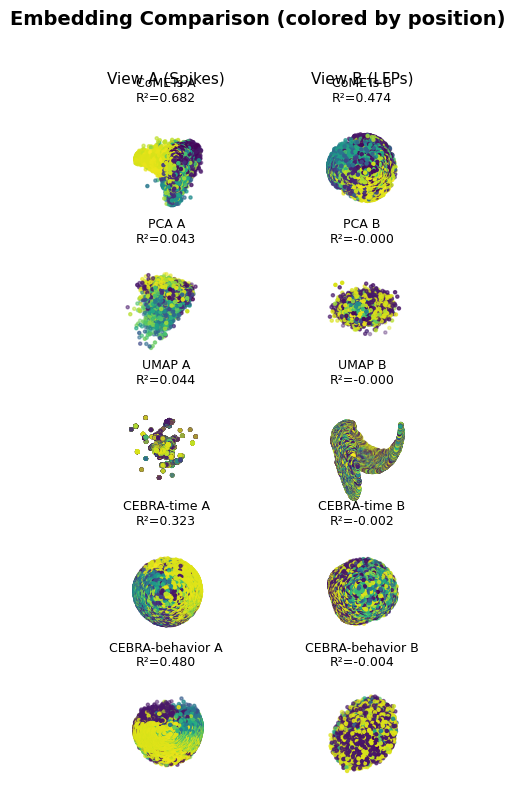

In [ ]:
# ============================================================
# VIZ 8: Compact Embedding Comparison (5x2 grid)
# ============================================================
print("\nGenerating compact embedding comparison...")

datasets_top_list = [
    ("CoMETs", ZA_comets),
    ("PCA", ZA_pca),
    ("UMAP", ZA_umap),
    ("CEBRA_time", ZA_cebra_time),
    ("CEBRA_behavior", ZA_cebra_behavior)
]
datasets_bot_list = [
    ("CoMETs", ZB_comets),
    ("PCA", ZB_pca),
    ("UMAP", ZB_umap),
    ("CEBRA_time", ZB_cebra_time),
    ("CEBRA_behavior", ZB_cebra_behavior)
]
titles_left = ["CoMETs", "PCA", "UMAP", "CEBRA-time", "CEBRA-behavior"]
col_titles = ["View A (Spikes)", "View B (LFPs)"]

view_angles_A = [(25, 35), (20, 45), (25, 60), (30, 30), (20, 70)]
view_angles_B = [(25, 35), (20, 45), (25, 60), (30, 30), (20, 70)]

fig, axes = plt.subplots(5, 2, figsize=(5, 9),
                         subplot_kw={'projection': '3d'},
                         gridspec_kw={'wspace': 0.02, 'hspace': 0.1})
color_viz, cmap, pos_color_label = build_position_colors(position_roi)

for r in range(5):
    nameA, ZA_ = datasets_top_list[r]
    axA = axes[r, 0]
    X, Y, Z = reduce_to_3d(ZA_)
    scatter_with_position_colors(axA, X, Y, Z, color_viz, cmap=cmap, s=5)
    axA.set_title(f"{titles_left[r]} A\nR2={decoding_scores[f'{nameA}_A']:.3f}", fontsize=9, pad=3)
    axA.view_init(*view_angles_A[r])

    nameB, ZB_ = datasets_bot_list[r]
    axB = axes[r, 1]
    X, Y, Z = reduce_to_3d(ZB_)
    scatter_with_position_colors(axB, X, Y, Z, color_viz, cmap=cmap, s=5)
    if f'{nameB}_B' in decoding_scores:
        titleB = f"{titles_left[r]} B\nR2={decoding_scores[f'{nameB}_B']:.3f}"
    else:
        titleB = f"{titles_left[r]} B"
    axB.set_title(titleB, fontsize=9, pad=3)
    axB.view_init(*view_angles_B[r])

    for ax in (axA, axB):
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_zticks([])
        ax.set_facecolor("white")
        ax.set_box_aspect([1, 1, 1])
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        ax.grid(False)
        ax.set_axis_off()
        for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
            axis.line.set_color((1, 1, 1, 0))

axes[0, 0].text2D(0.5, 1.15, col_titles[0], ha="center", va="bottom", fontsize=11, transform=axes[0, 0].transAxes)
axes[0, 1].text2D(0.5, 1.15, col_titles[1], ha="center", va="bottom", fontsize=11, transform=axes[0, 1].transAxes)

fig.text(0.5, 0.97, f"Embedding Comparison (colored by {pos_color_label})", ha="center", fontsize=14, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()



Generating predicted vs true position plots (2D XY)...


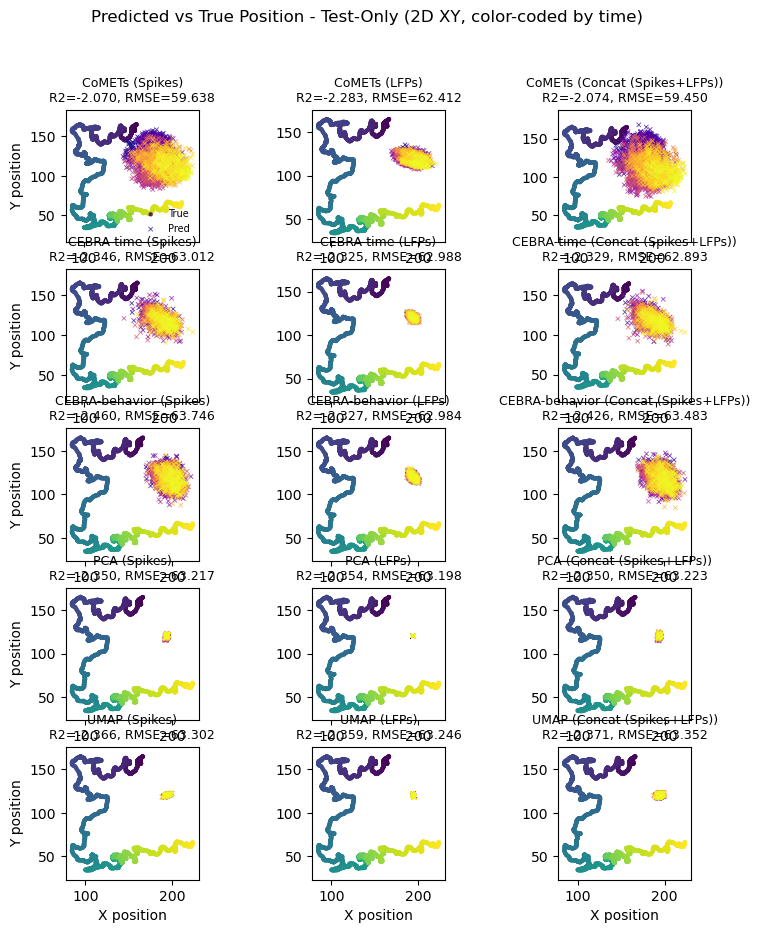

In [21]:
# ============================================================
# VIZ 9: Predicted vs True Position (Test-set only, 2D XY)
# ============================================================
print("\nGenerating predicted vs true position plots (2D XY)...")

Nshow = 3000
models_to_plot = ["CoMETs", "CEBRA_time", "CEBRA_behavior", "PCA", "UMAP"]
position_real = ensure_position_matrix(position_roi)

views = ["A", "B", "AB"]
fig, axes = plt.subplots(len(models_to_plot), len(views), figsize=(9, 10), sharex=False, sharey=False)
if len(models_to_plot) == 1:
    axes = np.expand_dims(axes, 0)

for i, model in enumerate(models_to_plot):
    for j, view in enumerate(views):
        ax = axes[i, j]
        rec = TRAJECTORY_PREDICTIONS.get((model, view), None)

        if rec is None:
            ax.text(0.5, 0.5, f"No record for {model} ({view})", ha="center", va="center", fontsize=9)
            ax.axis("off")
            continue

        yhat_test = ensure_position_matrix(rec["y_pred"])
        ntr = rec["ntr"]
        ytrue_test = position_real[ntr:]
        n = min(Nshow, len(ytrue_test), len(yhat_test))

        ytrue_n = ytrue_test[:n]
        yhat_n = yhat_test[:n]

        r2 = r2_score(ytrue_n, yhat_n)
        e = compute_rmse(ytrue_n, yhat_n)

        if view == "A":
            title_suffix = "Spikes"
        elif view == "B":
            title_suffix = "LFPs"
        else:
            title_suffix = "Concat (Spikes+LFPs)"

        title_name = f"{DISPLAY_NAMES[model]} ({title_suffix})"

        # 2D trajectory view: scatter in XY, color-coded by time.
        if ytrue_n.shape[1] >= 2 and yhat_n.shape[1] >= 2:
            t_idx = np.arange(n)

            ax.scatter(
                ytrue_n[:, 0], ytrue_n[:, 1],
                c=t_idx, cmap="viridis", s=10, alpha=0.85,
                marker="o", linewidths=0, label="True"
            )
            ax.scatter(
                yhat_n[:, 0], yhat_n[:, 1],
                c=t_idx, cmap="plasma", s=10, alpha=0.75,
                marker="x", linewidths=0.6, label="Pred"
            )

            # Force square XY visualization in each panel.
            ax.set_aspect("equal", adjustable="box")
            try:
                ax.set_box_aspect(1)
            except Exception:
                pass

            if i == 0 and j == 0:
                ax.legend(loc="best", fontsize=7, frameon=False)

            if i == len(models_to_plot) - 1:
                ax.set_xlabel("X position")
            if j == 0:
                ax.set_ylabel("Y position")
        else:
            # Fallback for 1D data
            plot_position_prediction(ax, ytrue_n, yhat_n, pred_color="tab:blue")
            if i == len(models_to_plot) - 1:
                ax.set_xlabel("Time")
            if j == 0:
                ax.set_ylabel("Position")

        ax.set_title(f"{title_name}\nR2={r2:.3f}, RMSE={e:.3f}", fontsize=9)

fig.suptitle("Predicted vs True Position - Test-Only (2D XY, color-coded by time)", fontsize=12, y=0.98)
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [ ]:
# ============================================================
# VIZ 9B: Predicted vs True Position (Training-set only, 2D XY)
# ============================================================
print("\nGenerating predicted vs true position plots (training-set only, 2D XY)...")

Nshow = 3000
models_to_plot = ["CoMETs", "CEBRA_time", "CEBRA_behavior", "PCA", "UMAP"]
position_real = ensure_position_matrix(position_roi)

views = ["A", "B", "AB"]
fig, axes = plt.subplots(len(models_to_plot), len(views), figsize=(9, 10), sharex=False, sharey=False)
if len(models_to_plot) == 1:
    axes = np.expand_dims(axes, 0)

for i, model in enumerate(models_to_plot):
    for j, view in enumerate(views):
        ax = axes[i, j]

        if view == "A":
            Z = EMBEDDINGS_A[model]
            title_suffix = "Spikes"
        elif view == "B":
            Z = EMBEDDINGS_B[model]
            title_suffix = "LFPs"
        else:
            Z = EMBEDDINGS_AB[model]
            title_suffix = "Concat (Spikes+LFPs)"

        Z = np.asarray(Z)
        y = ensure_position_matrix(position_real)
        n = min(len(Z), len(y))
        Z = Z[:n]
        y = y[:n]

        ntr = int(0.7 * n)
        if ntr < 2:
            ax.text(0.5, 0.5, f"Not enough training data for {model} ({view})",
                    ha="center", va="center", fontsize=9)
            ax.axis("off")
            continue

        Xtr, ytr = Z[:ntr], y[:ntr]
        dec = Ridge(alpha=1.0)
        dec.fit(Xtr, ytr)
        yhat_train = ensure_position_matrix(dec.predict(Xtr))

        nshow = min(Nshow, len(ytr), len(yhat_train))
        ytrue_n = ytr[:nshow]
        yhat_n = yhat_train[:nshow]

        r2 = r2_score(ytrue_n, yhat_n)
        e = compute_rmse(ytrue_n, yhat_n)

        title_name = f"{DISPLAY_NAMES[model]} ({title_suffix})"

        if ytrue_n.shape[1] >= 2 and yhat_n.shape[1] >= 2:
            t_idx = np.arange(nshow)
            ax.scatter(
                ytrue_n[:, 0], ytrue_n[:, 1],
                c=t_idx, cmap="viridis", s=10, alpha=0.85,
                marker="o", linewidths=0, label="True"
            )
            ax.scatter(
                yhat_n[:, 0], yhat_n[:, 1],
                c=t_idx, cmap="plasma", s=10, alpha=0.75,
                marker="x", linewidths=0.6, label="Pred"
            )

            ax.set_aspect("equal", adjustable="box")
            try:
                ax.set_box_aspect(1)
            except Exception:
                pass

            if i == 0 and j == 0:
                ax.legend(loc="best", fontsize=7, frameon=False)

            if i == len(models_to_plot) - 1:
                ax.set_xlabel("X position")
            if j == 0:
                ax.set_ylabel("Y position")
        else:
            plot_position_prediction(ax, ytrue_n, yhat_n, pred_color="tab:blue")
            if i == len(models_to_plot) - 1:
                ax.set_xlabel("Time")
            if j == 0:
                ax.set_ylabel("Position")

        ax.set_title(f"{title_name}\nTrain R2={r2:.3f}, RMSE={e:.3f}", fontsize=9)

fig.suptitle("Predicted vs True Position - Training-Only (2D XY, color-coded by time)", fontsize=12, y=0.98)
plt.show()



Generating bidirectional waveform recovery plots...


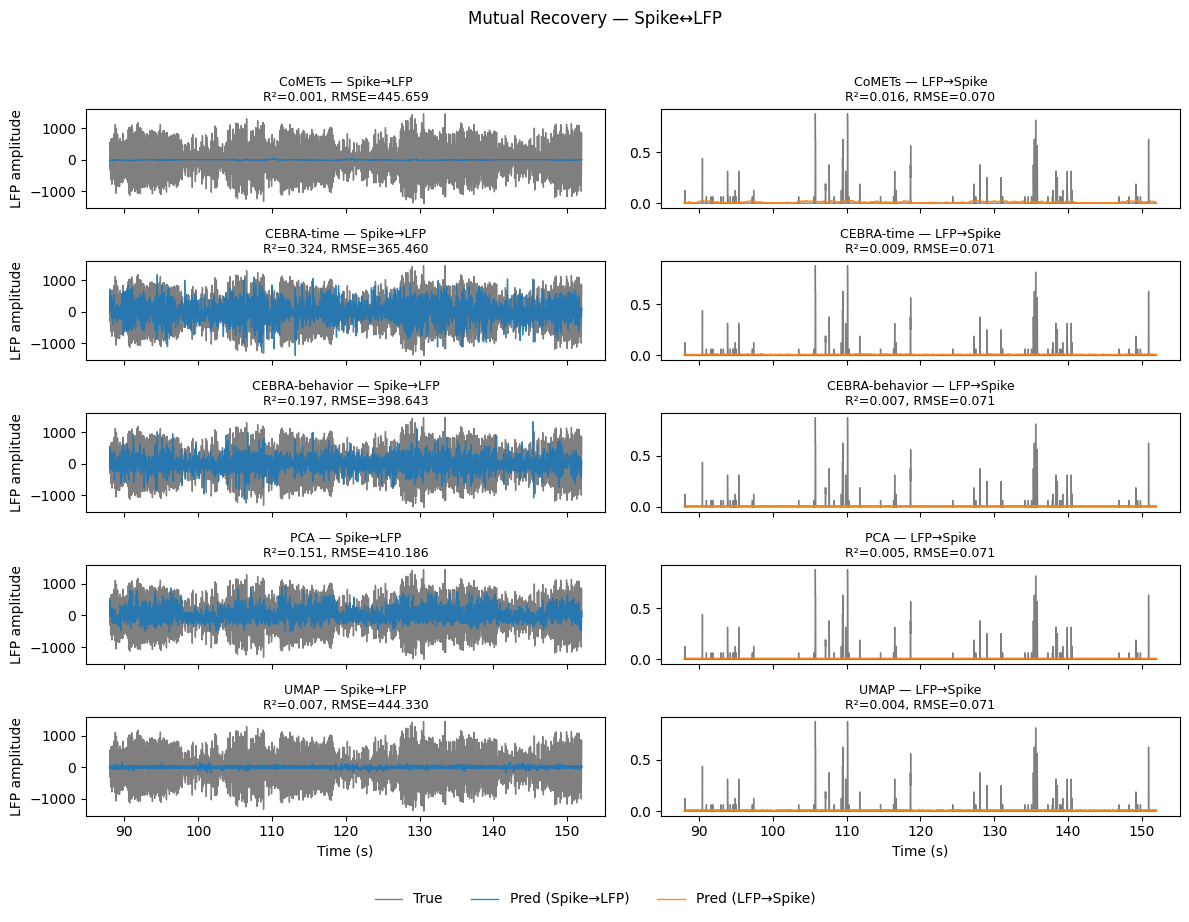

In [ ]:

# ============================================================
# VIZ 10: Bidirectional Waveform Recovery
# ============================================================
print("\nGenerating bidirectional waveform recovery plots...")

lfp_targets = np.asarray(lfp_roi)
spike_targets = np.asarray(spike_roi)
T, n_lfp = lfp_targets.shape
_, n_spk = spike_targets.shape

K_BLOCKS, BLOCK_FRAC = 3, 0.08
block_len = int(BLOCK_FRAC * T)
test_mask = np.zeros(T, dtype=bool)
centers = np.linspace(int(0.15*T), int(0.85*T), K_BLOCKS).astype(int)
for c in centers:
    s = max(0, c - block_len//2)
    e = min(T, s + block_len)
    test_mask[s:e] = True
train_mask = ~test_mask

def first_block_span(mask):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return None, None
    splits = np.where(np.diff(idx) > 1)[0]
    starts = np.r_[idx[0], idx[splits+1]]
    ends = np.r_[idx[splits], idx[-1]]
    return int(starts[0]), int(ends[0])

b0, b1 = first_block_span(test_mask)

pred_A2B, pred_B2A = {}, {}
metrics_A2B, metrics_B2A = {}, {}

for name in models_to_plot:
    # Spike â†’ LFP
    X_A = EMBEDDINGS_A[name]
    mA = Ridge(alpha=1.0)
    mA.fit(X_A[train_mask], lfp_targets[train_mask])
    Yhat_A = mA.predict(X_A)
    Y_true_A = lfp_targets
    r2_A = np.mean([r2_score(Y_true_A[test_mask, c], Yhat_A[test_mask, c]) for c in range(n_lfp)])
    err_A = compute_rmse(Y_true_A[test_mask], Yhat_A[test_mask])
    metrics_A2B[name] = (r2_A, err_A)
    pred_A2B[name] = mA.predict(X_A[b0:b1+1])

    # LFP â†’ Spike
    X_B = EMBEDDINGS_B[name]
    mB = Ridge(alpha=1.0)
    mB.fit(X_B[train_mask], spike_targets[train_mask])
    Yhat_B = mB.predict(X_B)
    Y_true_B = spike_targets
    r2_B = np.mean([r2_score(Y_true_B[test_mask, c], Yhat_B[test_mask, c]) for c in range(n_spk)])
    err_B = compute_rmse(Y_true_B[test_mask], Yhat_B[test_mask])
    metrics_B2A[name] = (r2_B, err_B)
    pred_B2A[name] = mB.predict(X_B[b0:b1+1])

t_block = np.arange(b0, b1+1) / fs_common
lfp_ch, spk_ch = 0, 0

fig, axes = plt.subplots(len(models_to_plot), 2,
                         figsize=(12, 9), sharex=True)

for i, name in enumerate(models_to_plot):
    axL = axes[i, 0]
    axL.plot(t_block, lfp_targets[b0:b1+1, lfp_ch], color="black", lw=1.0, alpha=0.5)
    axL.plot(t_block, pred_A2B[name][:, lfp_ch], color="tab:blue", lw=1.0, alpha=0.9)
    r2_A, err_A = metrics_A2B[name]
    axL.set_title(f"{DISPLAY_NAMES[name]} â€” Spikeâ†’LFP\nRÂ²={r2_A:.3f}, RMSE={err_A:.3f}", fontsize=9)
    if i == len(models_to_plot)-1:
        axL.set_xlabel("Time (s)")
    axL.set_ylabel("LFP amplitude")

    axR = axes[i, 1]
    axR.plot(t_block, spike_targets[b0:b1+1, spk_ch], color="black", lw=1.0, alpha=0.5)
    axR.plot(t_block, pred_B2A[name][:, spk_ch], color="tab:orange", lw=1.0, alpha=0.9)
    r2_B, err_B = metrics_B2A[name]
    axR.set_title(f"{DISPLAY_NAMES[name]} â€” LFPâ†’Spike\nRÂ²={r2_B:.3f}, RMSE={err_B:.3f}", fontsize=9)
    if i == len(models_to_plot)-1:
        axR.set_xlabel("Time (s)")

legend_elements = [
    plt.Line2D([0], [0], color='black', lw=1, label='True', alpha=0.5),
    plt.Line2D([0], [0], color='tab:blue', lw=1, label='Pred (Spikeâ†’LFP)', alpha=0.9),
    plt.Line2D([0], [0], color='tab:orange', lw=1, label='Pred (LFPâ†’Spike)', alpha=0.9)
]
fig.legend(handles=legend_elements, loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Mutual Recovery â€” Spikeâ†”LFP", fontsize=12, y=0.99)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()



Generating final figure with emphasized embeddings...


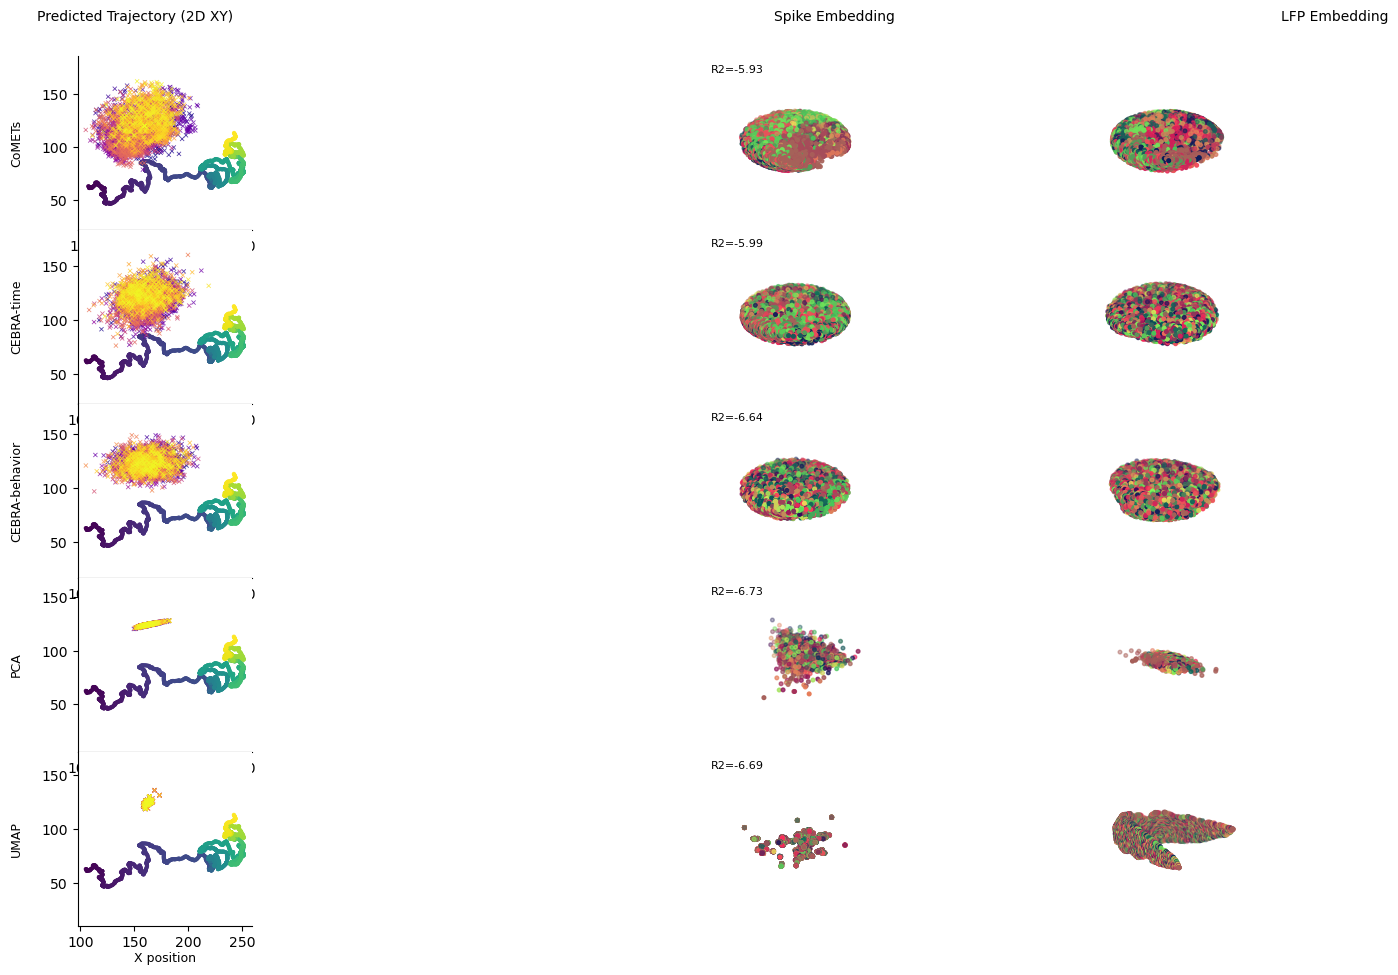


All visualizations complete.


In [ ]:
# ============================================================
# VIZ 11: Final Figure - Emphasized Embeddings (Consistent X-Axis)
# ============================================================
print("\nGenerating final figure with emphasized embeddings...")
model_colors = dict(CoMETs="tab:blue", CEBRA_time="tab:green", CEBRA_behavior='purple',
                    PCA="tab:orange", UMAP="tab:red")

color_viz, cmap, pos_color_label = build_position_colors(position_roi)
position_real = ensure_position_matrix(position_roi)

n_models = len(models_to_plot)
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(n_models, 3, width_ratios=[5, 2, 2], wspace=0.05, hspace=0.0)

for i, model in enumerate(models_to_plot):
    T_window = 10000

    ax1 = fig.add_subplot(gs[i, 0])
    rec = TRAJECTORY_PREDICTIONS.get((model, "A"), None)

    if rec is not None:
        yhat_test = ensure_position_matrix(rec["y_pred"])
        ntr = rec["ntr"]
        ytrue_test = position_real[ntr:]
        n = min(len(ytrue_test), len(yhat_test))
        n_show = min(T_window, n)

        ytrue_n = ytrue_test[:n_show]
        yhat_n = yhat_test[:n_show]

        if ytrue_n.shape[1] >= 2 and yhat_n.shape[1] >= 2:
            t_idx = np.arange(n_show)
            ax1.scatter(ytrue_n[:, 0], ytrue_n[:, 1], c=t_idx, cmap="viridis", s=9, alpha=0.85,
                        marker="o", linewidths=0)
            ax1.scatter(yhat_n[:, 0], yhat_n[:, 1], c=t_idx, cmap="plasma", s=9, alpha=0.75,
                        marker="x", linewidths=0.6)

            # Force square XY visualization in each recovery panel.
            ax1.set_aspect("equal", adjustable="box")
            try:
                ax1.set_box_aspect(1)
            except Exception:
                pass
        else:
            plot_position_prediction(
                ax1,
                ytrue_n,
                yhat_n,
                pred_color=model_colors.get(model.replace("-", "_"), "tab:gray"),
                lw_true=1.0,
                lw_pred=0.9
            )

    for spine in ["top", "right"]:
        ax1.spines[spine].set_visible(False)
    if i == n_models - 1:
        ax1.set_xlabel("X position", fontsize=9, labelpad=2)
    ax1.set_ylabel(DISPLAY_NAMES[model], rotation=90, fontsize=9, labelpad=18, va="center")

    ax2 = fig.add_subplot(gs[i, 1], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_A[model])
    scatter_with_position_colors(ax2, X, Y, Z, color_viz, cmap=cmap, s=7)
    ax2.view_init(25, 35)
    ax2.text2D(0.03, 0.90, f"R2={decoding_scores[f'{model}_A']:.2f}", transform=ax2.transAxes, fontsize=8)
    ax2.set_axis_off()
    ax2.set_box_aspect([5, 5, 2])

    ax3 = fig.add_subplot(gs[i, 2], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_B[model])
    scatter_with_position_colors(ax3, X, Y, Z, color_viz, cmap=cmap, s=7)
    ax3.view_init(25, 35)
    if f'{model}_B' in decoding_scores:
        ax3.text2D(0.03, 0.90, f"R2={decoding_scores[f'{model}_B']:.2f}", transform=ax3.transAxes, fontsize=8)
    ax3.set_axis_off()
    ax3.set_box_aspect([5, 5, 2])

plt.subplots_adjust(wspace=0.01, hspace=0.03, left=0.05, right=0.85, top=0.92, bottom=0.05)
fig.text(0.25, 0.955, "Predicted Trajectory (2D XY)", ha="center", fontsize=10)
fig.text(0.6, 0.955, "Spike Embedding", ha="center", fontsize=10)
fig.text(0.85, 0.955, "LFP Embedding", ha="center", fontsize=10)

plt.show()
print("\nAll visualizations complete.")



Generating final figure with embeddings...


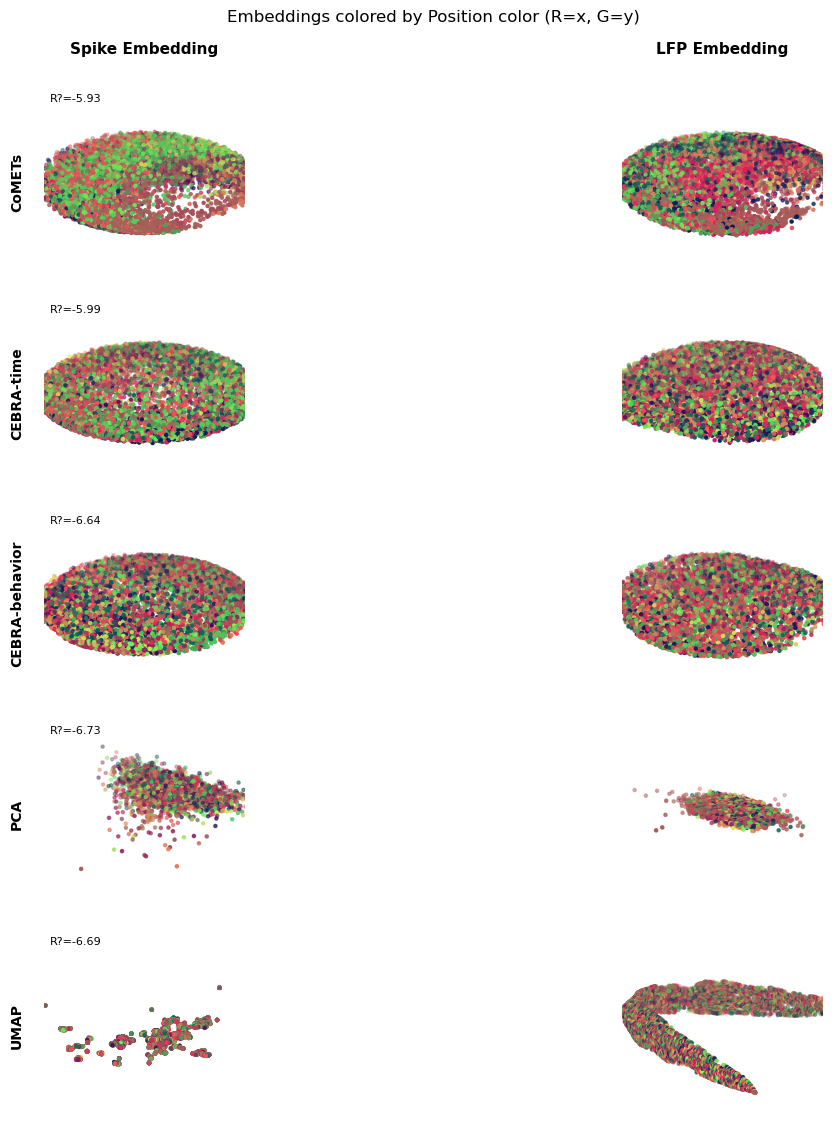


Visualization complete.


In [ ]:
# ============================================================
# Final Figure - Embeddings Only (5x2)
# ============================================================
print("\nGenerating final figure with embeddings...")

models_to_plot = ["CoMETs", "CEBRA_time", "CEBRA_behavior", "PCA", "UMAP"]
n_models = len(models_to_plot)
color_viz, cmap, pos_color_label = build_position_colors(position_roi)

# Zoom ratio for 3D plots (adjust this value to zoom in/out)
zoom_ratio = 1.5  # >1 zooms in, <1 zooms out

fig = plt.figure(figsize=(12, 12))
gs = fig.add_gridspec(
    n_models, 2,
    wspace=0.15, hspace=0.05,
    left=0.05, right=0.95, top=0.92, bottom=0.05
)

for i, model in enumerate(models_to_plot):
    # Spike embedding (left)
    ax1 = fig.add_subplot(gs[i, 0], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_A[model])
    scatter_with_position_colors(ax1, X, Y, Z, color_viz, cmap=cmap, s=5)
    ax1.view_init(25, 35)

    x_range = X.max() - X.min()
    y_range = Y.max() - Y.min()
    z_range = Z.max() - Z.min()
    x_center = (X.max() + X.min()) / 2
    y_center = (Y.max() + Y.min()) / 2
    z_center = (Z.max() + Z.min()) / 2

    ax1.set_xlim(x_center - x_range / (2 * zoom_ratio), x_center + x_range / (2 * zoom_ratio))
    ax1.set_ylim(y_center - y_range / (2 * zoom_ratio), y_center + y_range / (2 * zoom_ratio))
    ax1.set_zlim(z_center - z_range / (2 * zoom_ratio), z_center + z_range / (2 * zoom_ratio))

    ax1.text2D(0.03, 0.90, f"R?={decoding_scores[f'{model}_A']:.2f}",
               transform=ax1.transAxes, fontsize=8)
    ax1.set_axis_off()
    ax1.set_box_aspect([5, 5, 1])

    if i == 0:
        ax1.set_title("Spike Embedding", fontsize=11, weight="bold", pad=20)
    ax1.text2D(-0.1, 0.5, DISPLAY_NAMES[model], transform=ax1.transAxes,
               fontsize=10, weight="bold", rotation=90, va="center", ha="right")

    # LFP embedding (right)
    ax2 = fig.add_subplot(gs[i, 1], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_B[model])
    scatter_with_position_colors(ax2, X, Y, Z, color_viz, cmap=cmap, s=5)
    ax2.view_init(25, 35)

    x_range = X.max() - X.min()
    y_range = Y.max() - Y.min()
    z_range = Z.max() - Z.min()
    x_center = (X.max() + X.min()) / 2
    y_center = (Y.max() + Y.min()) / 2
    z_center = (Z.max() + Z.min()) / 2

    ax2.set_xlim(x_center - x_range / (2 * zoom_ratio), x_center + x_range / (2 * zoom_ratio))
    ax2.set_ylim(y_center - y_range / (2 * zoom_ratio), y_center + y_range / (2 * zoom_ratio))
    ax2.set_zlim(z_center - z_range / (2 * zoom_ratio), z_center + z_range / (2 * zoom_ratio))

    if f'{model}_B' in decoding_scores:
        ax2.text2D(0.03, 0.90, f"R?={decoding_scores[f'{model}_B']:.2f}",
                   transform=ax2.transAxes, fontsize=8)
    ax2.set_axis_off()
    ax2.set_box_aspect([5, 5, 1])

    if i == 0:
        ax2.set_title("LFP Embedding", fontsize=11, weight="bold", pad=20)

fig.suptitle(f"Embeddings colored by {pos_color_label}", fontsize=12, y=0.98)
plt.show()

print("\nVisualization complete.")



Generating trajectory-only figure...


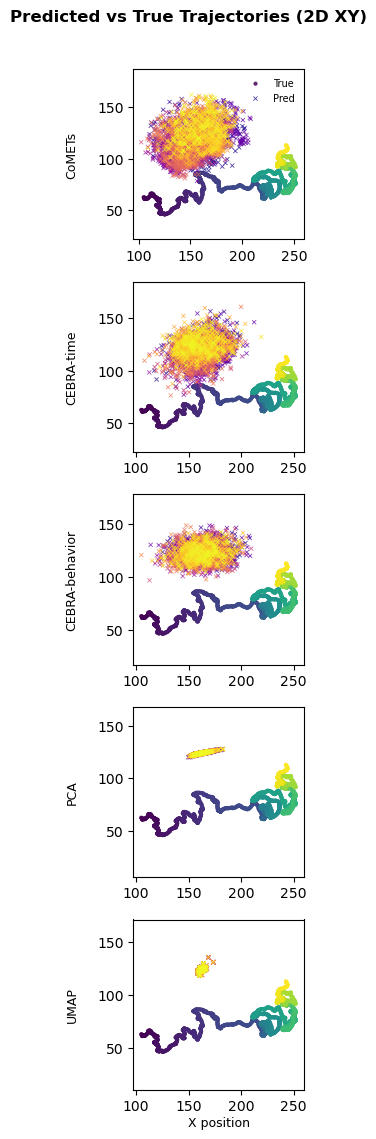


Trajectory-only visualization complete.


In [ ]:
# ============================================================
# VIZ 11: Predicted Trajectories Only (Clean Version)
# ============================================================
print("\nGenerating trajectory-only figure...")

# ------------------------------------------------------------
# Setup
# ------------------------------------------------------------
model_colors = dict(
    CoMETs="tab:blue",
    CEBRA_time="tab:green",
    CEBRA_behavior="purple",
    PCA="tab:orange",
    UMAP="tab:red"
)

T_window = 10000   # number of samples to visualize
n_models = len(models_to_plot)
position_real = ensure_position_matrix(position_roi)

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(6, 2.4 * n_models),
    sharex=False,
    constrained_layout=False
)

if n_models == 1:
    axes = [axes]

for i, (ax, model) in enumerate(zip(axes, models_to_plot)):
    rec = TRAJECTORY_PREDICTIONS.get((model, "A"), None)

    if rec is not None:
        yhat_test = ensure_position_matrix(rec["y_pred"])
        ntr = rec["ntr"]
        ytrue_test = position_real[ntr:]
        n = min(len(ytrue_test), len(yhat_test))
        n_show = min(T_window, n)

        ytrue_n = ytrue_test[:n_show]
        yhat_n = yhat_test[:n_show]

        if ytrue_n.shape[1] >= 2 and yhat_n.shape[1] >= 2:
            t_idx = np.arange(n_show)
            ax.scatter(ytrue_n[:, 0], ytrue_n[:, 1], c=t_idx, cmap="viridis", s=9, alpha=0.85,
                       marker="o", linewidths=0, label="True")
            ax.scatter(yhat_n[:, 0], yhat_n[:, 1], c=t_idx, cmap="plasma", s=9, alpha=0.75,
                       marker="x", linewidths=0.6, label="Pred")

            # Force square XY visualization per subplot.
            ax.set_aspect("equal", adjustable="box")
            try:
                ax.set_box_aspect(1)
            except Exception:
                pass

            if i == 0:
                ax.legend(loc="best", fontsize=7, frameon=False)
            if i == n_models - 1:
                ax.set_xlabel("X position", fontsize=9, labelpad=2)
            ax.set_ylabel(DISPLAY_NAMES[model], rotation=90, fontsize=9, labelpad=18, va="center")
        else:
            plot_position_prediction(
                ax,
                ytrue_n,
                yhat_n,
                pred_color=model_colors.get(model.replace("-", "_"), "tab:gray"),
                lw_true=1.0,
                lw_pred=0.9
            )
            for spine in ["top", "left", "right"]:
                ax.spines[spine].set_visible(False)
            ax.spines["bottom"].set_visible(True)
            ax.spines["bottom"].set_linewidth(1.2)
            ax.spines["bottom"].set_color("black")
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
            if i == n_models - 1:
                ax.set_xlabel("Time (samples)", fontsize=9, labelpad=2)
            ax.set_ylabel(DISPLAY_NAMES[model], rotation=90, fontsize=9, labelpad=18, va="center")

plt.subplots_adjust(
    hspace=0.25,
    left=0.12, right=0.98,
    top=0.93, bottom=0.08
)

fig.text(0.5, 0.97, "Predicted vs True Trajectories (2D XY)",
         ha="center", fontsize=12, weight="bold")

plt.show()

print("\nTrajectory-only visualization complete.")
